# Customer churn: data audit and development-only EDA

**Question:** which account and service patterns help prioritize a limited retention workload? The target records churn within the last month. This static dataset supports retrospective classification, not a causal claim about preventable departures.

Data: [IBM sample / BlastChar on Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). Download the original CSV as described in `data/README.md`; the dataset is not redistributed. This notebook exports aggregate summaries only.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from churn.data import DATA_FILE, load_data, split_indices, profile_groups

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports"
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})

## 1. Validate schema and reserve the holdout

The loader parses types without fitting transformations. Split eligibility excludes historical evaluation customers and repeated profiles. All later EDA is restricted to development rows; test labels are used only for stratification. Historical full-data exposure cannot be undone.

In [2]:
X, y, raw = load_data(ROOT / "data/raw" / DATA_FILE)
development, holdout = split_indices(y, X)
Xd, yd = X.iloc[development].copy(), y.iloc[development].copy()
del raw
assert not set(profile_groups(Xd)) & set(profile_groups(X.iloc[holdout]))
display(pd.Series({"total_rows": len(X), "predictors": X.shape[1],
                   "development_rows": len(development), "reserved_holdout_rows": len(holdout),
                   "development_churn_rate": yd.mean()}, name="Dataset audit").to_frame())

                        Dataset audit
total_rows                7043.000000
predictors                  19.000000
development_rows          5634.000000
reserved_holdout_rows     1409.000000
development_churn_rate       0.265886

## 2. Missingness and repeated profiles

Zero-tenure billing blanks may be structurally meaningful. The original approach filled them with zero. Improved pipelines learn a median from each training fold. This is a defensible robustness change, not an isolated, measured source of accuracy gain. Identical profiles are retained, because distinct customers can share a profile, but grouped CV keeps them together.

In [3]:
audit = pd.DataFrame({"dtype": Xd.dtypes.astype(str), "missing": Xd.isna().sum(),
                      "unique_values": Xd.nunique()})
display(audit)
missing = Xd.TotalCharges.isna()
display(pd.Series({"blank_billing_totals": int(missing.sum()),
                   "blanks_all_zero_tenure": bool(Xd.loc[missing, "tenure"].eq(0).all()),
                   "repeated_predictor_rows": int(pd.Series(profile_groups(Xd)).duplicated().sum())},
                  name="Development checks").to_frame())

                    dtype  missing  unique_values
gender             object        0              2
SeniorCitizen      object        0              2
Partner            object        0              2
Dependents         object        0              2
tenure              int64        0             73
PhoneService       object        0              2
MultipleLines      object        0              3
InternetService    object        0              3
OnlineSecurity     object        0              3
OnlineBackup       object        0              3
DeviceProtection   object        0              3
TechSupport        object        0              3
StreamingTV        object        0              3
StreamingMovies    object        0              3
Contract           object        0              3
PaperlessBilling   object        0              2
PaymentMethod      object        0              4
MonthlyCharges    float64        0           1509
TotalCharges      float64        7           5273

                        Development checks
blank_billing_totals                     7
blanks_all_zero_tenure                True
repeated_predictor_rows                 40

## 3. Imbalance and a meaningful baseline

Roughly one in four customers churn. Predicting everyone stays can look accurate while detecting no churners. Average precision is the main ranking metric, with no-skill AP equal to the evaluation prevalence. Precision, recall, F1 and confusion counts describe the contact workload at a stated threshold.

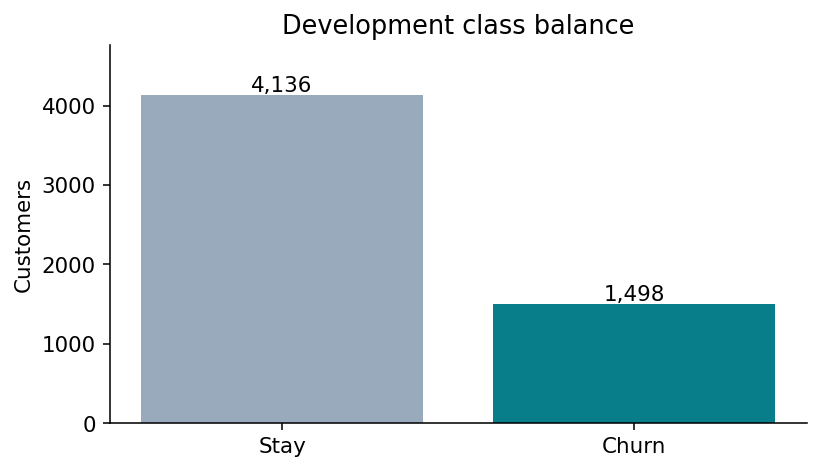

In [4]:
counts = yd.value_counts().reindex([0, 1])
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(["Stay", "Churn"], counts, color=["#9aaabd", "#087e8b"])
for i, value in enumerate(counts):
    ax.text(i, value + 40, f"{value:,}", ha="center")
ax.set(title="Development class balance", ylabel="Customers", ylim=(0, counts.max()*1.15))
plt.tight_layout(); plt.show()

## 4. Account and service patterns

Compare rates rather than raw churn counts so segment size is visible. These are development-only associations; contractual commitment and service mix can proxy for unmeasured customer differences.

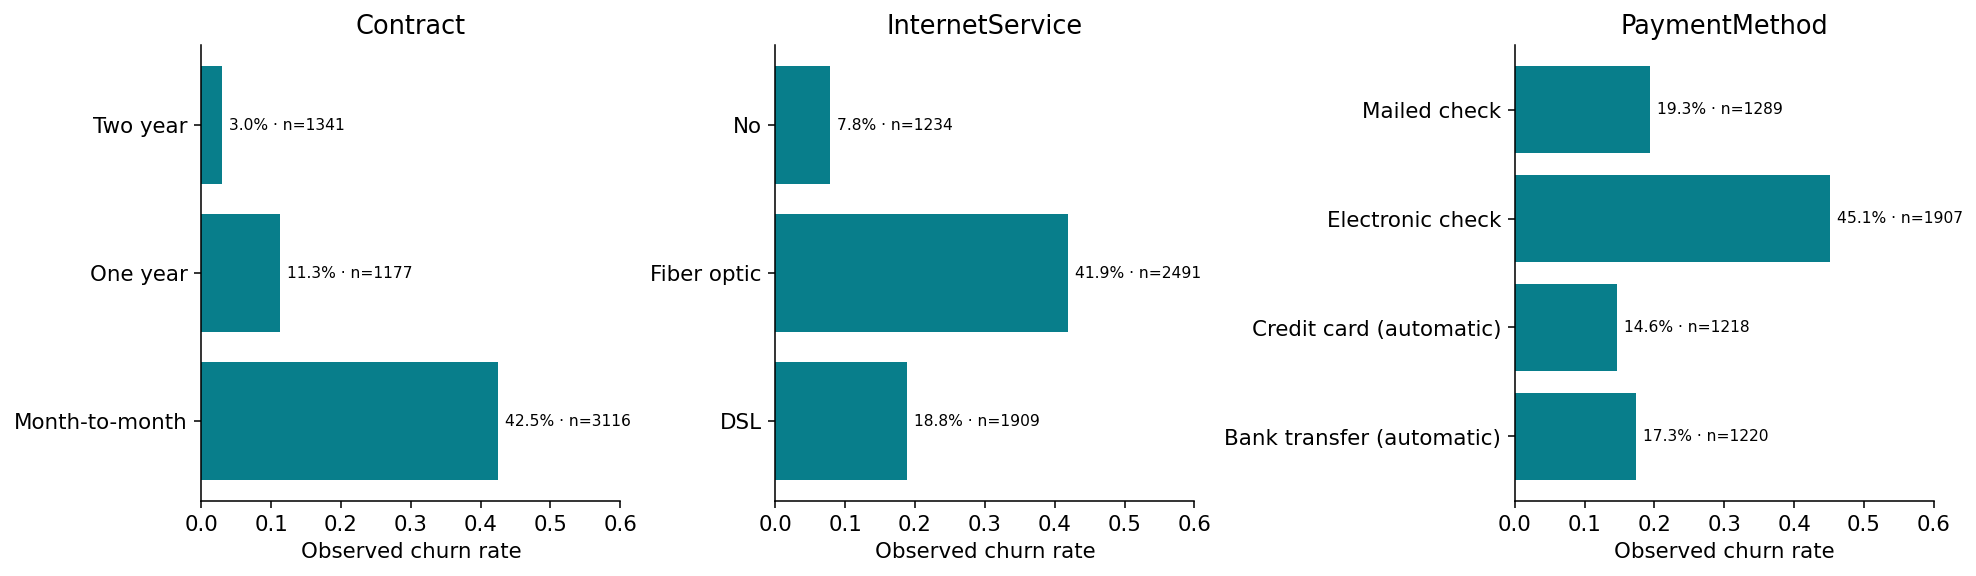

                customers  churn_rate
Contract                             
Month-to-month       3116    0.425225
One year             1177    0.112999
Two year             1341    0.029828

                 customers  churn_rate
InternetService                       
DSL                   1909    0.188057
Fiber optic           2491    0.418707
No                    1234    0.077796

                           customers  churn_rate
PaymentMethod                                   
Bank transfer (automatic)       1220    0.172951
Credit card (automatic)         1218    0.146141
Electronic check                1907    0.450970
Mailed check                    1289    0.193173

In [5]:
eda = Xd.assign(Churn=yd)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
for ax, feature in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    summary = eda.groupby(feature).Churn.agg(customers="count", churn_rate="mean")
    ax.barh(summary.index, summary.churn_rate, color="#087e8b")
    ax.set(xlabel="Observed churn rate", title=feature, xlim=(0, .6))
    for i, row in enumerate(summary.itertuples()):
        ax.text(row.churn_rate + .01, i, f"{row.churn_rate:.1%} · n={row.customers}", va="center", fontsize=8)
plt.show()
for feature in ["Contract", "InternetService", "PaymentMethod"]:
    display(eda.groupby(feature).Churn.agg(customers="count", churn_rate="mean"))

## 5. Tenure and correlated charges

Accumulated charges and tenure are related, making coefficient signs difficult to interpret in isolation. Test nonlinear numeric effects with a compact spline basis; do not assume that extra ratios help.

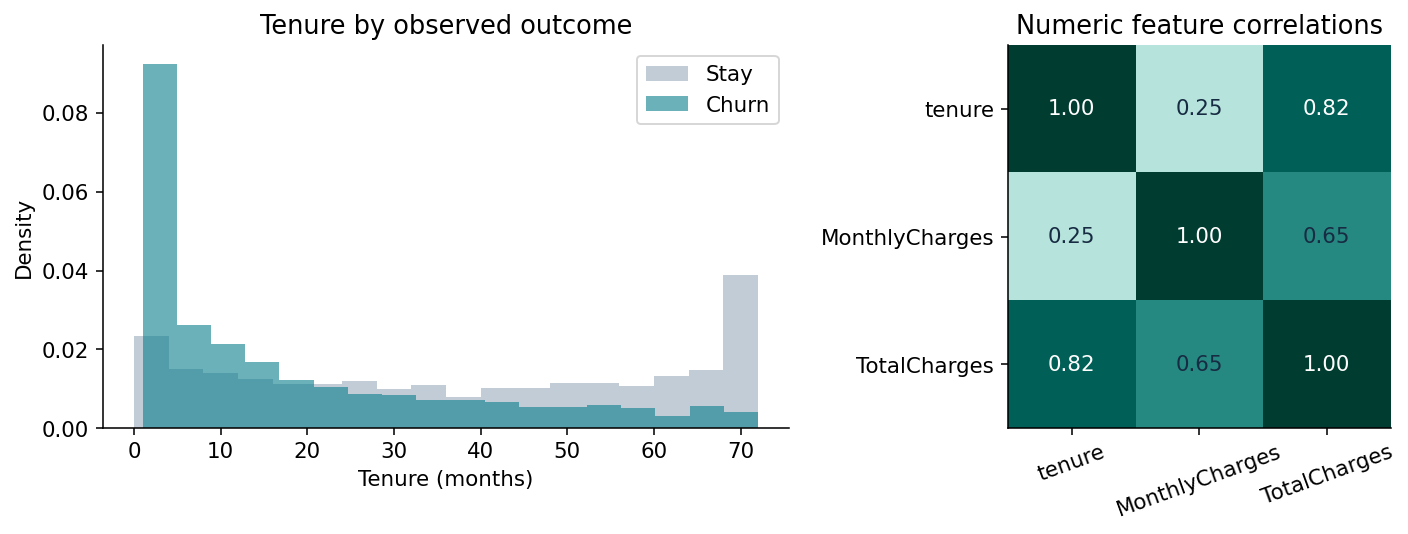

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), layout="constrained")
for label, color in [(0, "#9aaabd"), (1, "#087e8b")]:
    axes[0].hist(Xd.loc[yd.eq(label), "tenure"], bins=18, density=True,
                 alpha=.6, color=color, label="Churn" if label else "Stay")
axes[0].set(title="Tenure by observed outcome", xlabel="Tenure (months)", ylabel="Density")
axes[0].legend()
corr = Xd[["tenure", "MonthlyCharges", "TotalCharges"]].corr()
im = axes[1].imshow(corr, vmin=-1, vmax=1, cmap="BrBG")
axes[1].set(xticks=range(3), yticks=range(3), xticklabels=corr.columns,
            yticklabels=corr.columns, title="Numeric feature correlations")
axes[1].tick_params(axis="x", rotation=20)
for i in range(3):
    for j in range(3):
        axes[1].text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center",
                     color="white" if abs(corr.iloc[i,j])>.7 else "#172b42")
plt.show()

## Modelling decisions

- Drop customer ID and keep the target out of all feature transforms.
- Keep preprocessing inside each training fold; group identical profiles in nested CV.
- Compare original models with regularized linear and spline logistic regression and histogram boosting.
- Tune ranking by AP, choose the operating threshold on development predictions, then evaluate the reserved holdout.
- Before operational use, obtain timestamped pre-outcome features, test temporal generalization, inspect calibration and subgroup errors, and measure incremental outreach value.

Continue with `02_experiments_and_business_results.ipynb`.